# Berlin LOR Watering Equity and Environmental Need

## Do citizen watering patterns align with neighbourhood vulnerability?

**Objective.** Join the May 2020-December 2025 inventory-normalized recorded
citizen-watering measures
to the official Monitoring Soziale Stadtentwicklung (MSS) 2025 and Berlin
Environmental Justice 2023/24 indicators at Planungsraum level.

**Primary questions.**

1. Is watering reach lower in more socially disadvantaged neighbourhoods?
2. Is watering higher where thermal burden or poor green provision indicate need?
3. Which Planungsräume combine social disadvantage, environmental need, and
   below-median recorded watering reach?

This is a preliminary, cross-sectional, descriptive, and hypothesis-generating
equity analysis. Because the results informed H3, they are not an independent
confirmatory test. It does not estimate causal effects or unobserved watering
outside the Giess den Kiez platform.

## Analysis plan

1. Validate the official LOR joins and exclude MSS records marked invalid.
2. Compare watering reach and intensity across social and environmental classes.
3. Estimate citywide Spearman and district-adjusted rank associations.
4. Check whether conclusions are sensitive to small tree-inventory denominators.
5. Identify transparent screening candidates for subsequent field validation;
   these are not validated allocation priorities.

MSS values refer to 31 December 2024. The environmental-justice indicators refer
to 2023/24. Watering outcomes are cumulative from May 2020 through December
2025; May 2020 is partial and the complete calendar years are 2021-2025.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, kruskal
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
np.random.seed(42)


def find_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data/spatial/lor_equity_environment_2024.gpkg").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_root()
EQUITY_FILE = ROOT / "data/spatial/lor_equity_environment_2024.gpkg"
WATERING_FILE = ROOT / "output/spatial/lor_watering_metrics_2020_2025.gpkg"
OUT = ROOT / "output/equity"
FIGURES = OUT / "figures"
TABLES = OUT / "tables"
for folder in [FIGURES, TABLES]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {
    "green": "#26734d",
    "blue": "#337ab7",
    "orange": "#d9822b",
    "red": "#b23a48",
    "gray": "#d9d9d9",
}

print(f"Project root discovered: {ROOT.name}")
print(f"Watering polygons: {WATERING_FILE.name}")
print(f"Equity indicators: {EQUITY_FILE.name}")

Project root discovered: MasterThesis
Watering polygons: lor_watering_metrics_2020_2025.gpkg
Equity indicators: lor_equity_environment_2024.gpkg


## 1. Load and validate the LOR-level sources

In [2]:
watering = gpd.read_file(WATERING_FILE, layer="lor_watering_metrics")
mss_status = gpd.read_file(EQUITY_FILE, layer="mss2025_indizes_542")
mss_indicators = gpd.read_file(EQUITY_FILE, layer="mss2025_indexind_542")
environment = gpd.read_file(
    EQUITY_FILE,
    layer="environmental_justice_2023_2024",
)

for name, frame in {
    "watering": watering,
    "mss_status": mss_status,
    "mss_indicators": mss_indicators,
    "environment": environment,
}.items():
    assert len(frame) == 542, f"{name}: unexpected LOR count."
    assert frame["plr_id"].is_unique, f"{name}: duplicate plr_id."
    assert str(frame.crs) == "EPSG:25833", f"{name}: unexpected CRS."

reference_ids = set(watering["plr_id"])
assert all(
    set(frame["plr_id"]) == reference_ids
    for frame in [mss_status, mss_indicators, environment]
)

# Compare geometries, but join attributes by the stable official plr_id.
# The 2023/24 Environmental Justice service contains localized boundary updates.
reference_area = watering.set_index("plr_id").geometry.area.sort_index()
geometry_differences = {}
for name, frame in {
    "MSS 2025 status indices": mss_status,
    "MSS 2025 component indicators": mss_indicators,
    "Environmental Justice 2023/24": environment,
}.items():
    comparison_area = frame.set_index("plr_id").geometry.area.sort_index()
    relative_difference = (
        (reference_area - comparison_area).abs() / reference_area
    )
    geometry_differences[name] = float(relative_difference.max())
    assert relative_difference.max() < 0.05

assert (
    watering.set_index("plr_id")["plr_name"].sort_index()
    == environment.set_index("plr_id")["plr_name"].sort_index()
).all()

join_audit = pd.DataFrame(
    {
        "source": [
            "Watering metrics",
            "MSS 2025 status indices",
            "MSS 2025 component indicators",
            "Environmental Justice 2023/24",
        ],
        "lor_features": [
            len(watering),
            len(mss_status),
            len(mss_indicators),
            len(environment),
        ],
        "unique_lor_ids": [
            watering["plr_id"].nunique(),
            mss_status["plr_id"].nunique(),
            mss_indicators["plr_id"].nunique(),
            environment["plr_id"].nunique(),
        ],
        "crs": [
            str(watering.crs),
            str(mss_status.crs),
            str(mss_indicators.crs),
            str(environment.crs),
        ],
        "max_relative_area_difference_pct": [
            0,
            100 * geometry_differences["MSS 2025 status indices"],
            100 * geometry_differences["MSS 2025 component indicators"],
            100 * geometry_differences["Environmental Justice 2023/24"],
        ],
    }
)
join_audit.to_csv(TABLES / "equity_join_audit.csv", index=False)
display(join_audit)

,source,lor_features,unique_lor_ids,crs,max_relative_area_difference_pct
0,Watering metrics,542,542,EPSG:25833,0.000
1,MSS 2025 status indices,542,542,EPSG:25833,0.000
2,MSS 2025 component indicators,542,542,EPSG:25833,0.000
3,Environmental Justice 2023/24,542,542,EPSG:25833,4.550


In [3]:
mss_status_attrs = mss_status[
    [
        "plr_id", "ew", "di_n", "di_v", "sdi", "sdi_n", "sdi_v",
        "si_n", "si_v", "zeit", "kom",
    ]
].rename(
    columns={
        "ew": "mss_population",
        "zeit": "mss_reference_date",
        "kom": "mss_validity",
    }
)

mss_indicator_attrs = mss_indicators[
    ["plr_id", "s1", "s2", "s3", "s4", "kom"]
].rename(columns={"kom": "indicator_validity"})

environment_attrs = environment.drop(columns=["geometry", "plr_name"]).rename(
    columns={
        "kategorie": "multiple_burden",
        "bioklima": "thermal_burden",
        "gruenvers": "green_provision",
        "laerm": "noise_burden",
        "luft": "air_burden",
        "status_ind": "ej_social_status",
        "einwohner": "ej_population_class",
        "wol_l_l": "simple_housing_noise_air",
    }
)

panel = (
    watering.merge(mss_status_attrs, on="plr_id", how="left", validate="one_to_one")
    .merge(mss_indicator_attrs, on="plr_id", how="left", validate="one_to_one")
    .merge(environment_attrs, on="plr_id", how="left", validate="one_to_one")
)

panel["social_status_score"] = panel["si_n"].replace(-9999, np.nan)
panel["thermal_burden_score"] = panel["thermal_burden"].map(
    {"gering": 1, "mittel": 2, "hoch": 3}
)
panel["green_deficit_score"] = panel["green_provision"].map(
    {"gut": 1, "mittel": 2, "schlecht": 3}
)
panel["multiple_burden_count"] = panel["multiple_burden"].map(
    {
        "keine starke Belastung": 0,
        "einfach": 1,
        "zweifach": 2,
        "dreifach": 3,
        "vierfach": 4,
        "fünffach": 5,
    }
)

analysis = panel[
    (panel["inventory_trees"] > 0)
    & panel["mss_validity"].eq("gültig")
].copy()

analysis_summary = pd.DataFrame(
    {
        "metric": [
            "All Planungsräume",
            "Valid MSS observations with inventoried trees",
            "Excluded invalid MSS observations",
            "Median watering reach (%)",
            "Median litres per inventory tree",
        ],
        "value": [
            len(panel),
            len(analysis),
            int((~panel["mss_validity"].eq("gültig")).sum()),
            analysis["watering_reach_pct"].median(),
            analysis["litres_per_inventory_tree"].median(),
        ],
    }
)
display(analysis_summary)

,metric,value
0,All Planungsräume,542.000
1,Valid MSS observations with inventoried trees,535.000
2,Excluded invalid MSS observations,7.000
3,Median watering reach (%),0.663
4,Median litres per inventory tree,1.170


### Indicator interpretation

- `S1`: unemployment under SGB II among working-age residents (%).
- `S2`: children and adolescents in single-parent households (%).
- `S3`: non-unemployed recipients of SGB II/SGB XII transfers (%).
- `S4`: children under 15 in SGB II benefit communities (%), used here as
  the MSS child-poverty measure.
- MSS social status runs from `1 = high` to `4 = very low`.
- Environmental-justice burden counts how many of thermal, green, noise, air,
  and social indicators fall in the least favourable category.

Sources: the official MSS 2025 indicator documentation and Berlin Environmental
Atlas 2023/24 methodology.

The Environmental Justice service uses the same 542 IDs and names but contains
localized boundary differences of up to about 4.8% in polygon area relative to
the 2021 LOR layer. This notebook joins attributes by `plr_id` and retains the
watering analysis geometry.

## 2. Map watering, social status, and environmental need

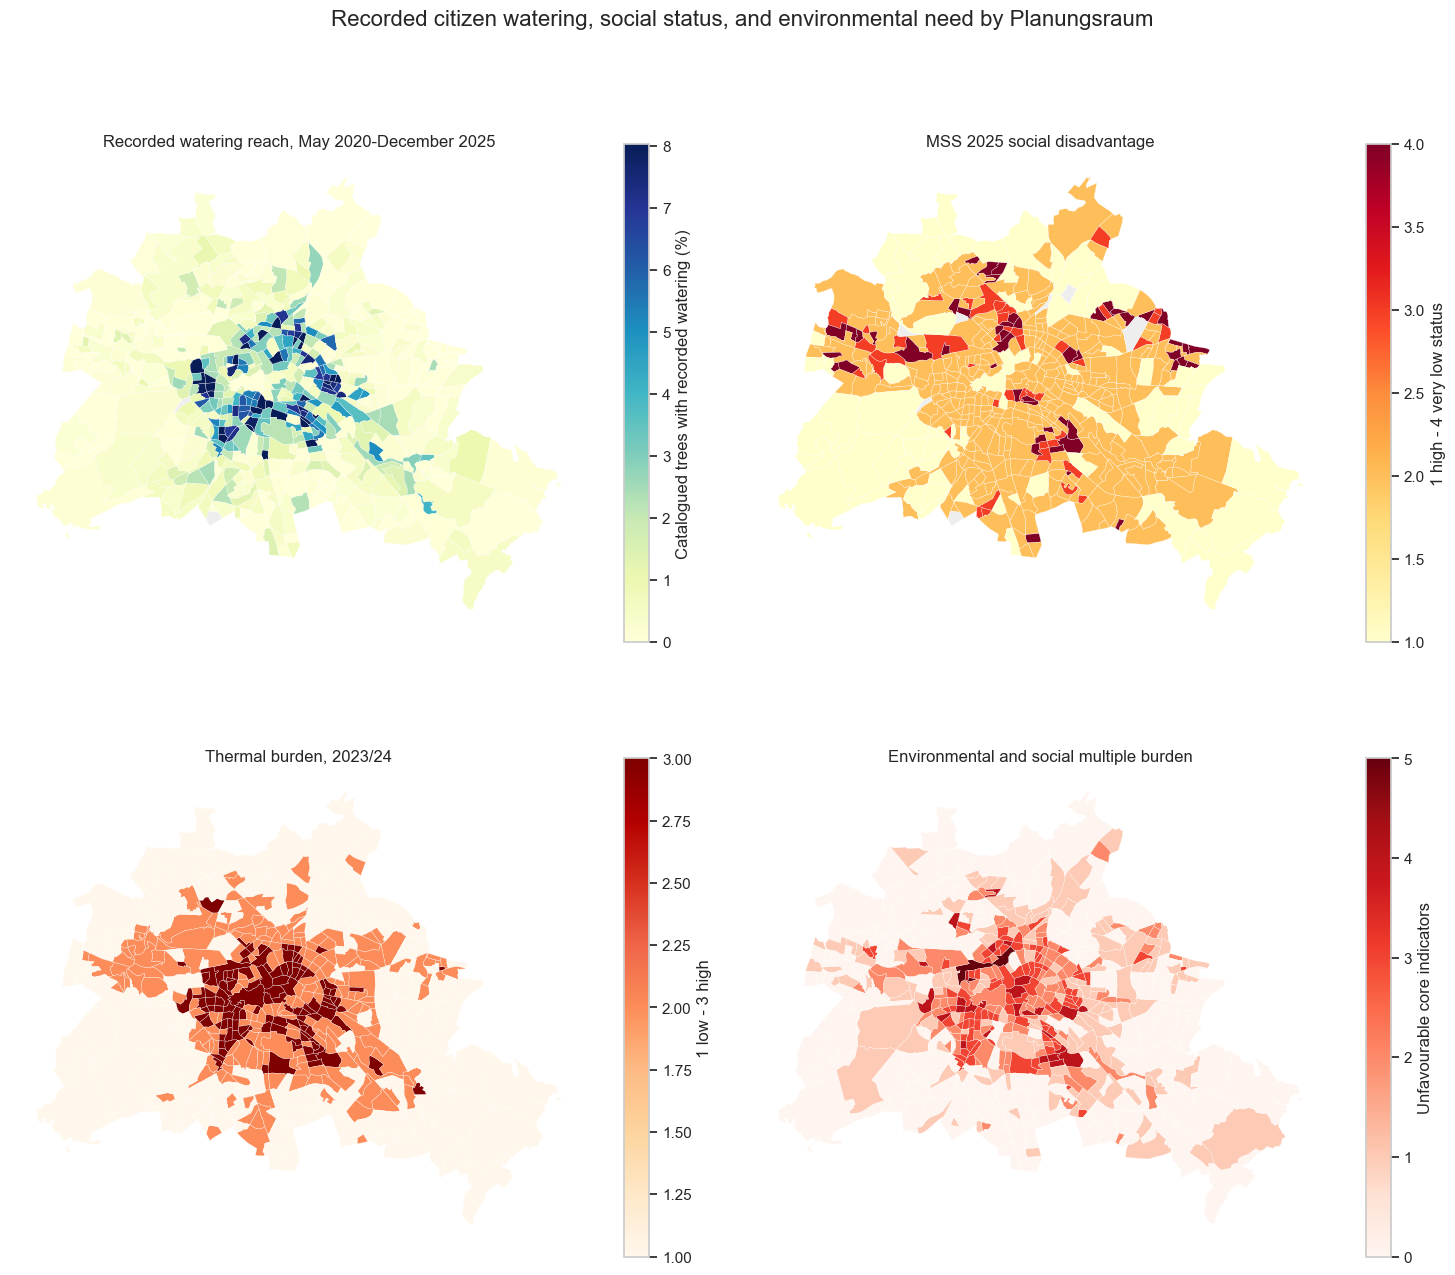

In [4]:
map_panel = panel.copy()
map_panel.loc[
    ~map_panel["mss_validity"].eq("gültig"),
    "social_status_score",
] = np.nan

reach_cap = map_panel["watering_reach_pct"].quantile(0.95)
map_specs = [
    (
        "watering_reach_pct",
        "Recorded watering reach, May 2020-December 2025",
        "YlGnBu",
        0,
        reach_cap,
        "Catalogued trees with recorded watering (%)",
    ),
    (
        "social_status_score",
        "MSS 2025 social disadvantage",
        "YlOrRd",
        1,
        4,
        "1 high - 4 very low status",
    ),
    (
        "thermal_burden_score",
        "Thermal burden, 2023/24",
        "OrRd",
        1,
        3,
        "1 low - 3 high",
    ),
    (
        "multiple_burden_count",
        "Environmental and social multiple burden",
        "Reds",
        0,
        5,
        "Unfavourable core indicators",
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 14))
for ax, (column, title, cmap, vmin, vmax, label) in zip(axes.flat, map_specs):
    map_panel.plot(
        column=column,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        edgecolor="white",
        linewidth=0.2,
        legend=True,
        legend_kwds={"label": label, "shrink": 0.7},
        missing_kwds={"color": "#eeeeee", "label": "Not classified"},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_axis_off()

fig.suptitle(
    "Recorded citizen watering, social status, and environmental need by Planungsraum",
    fontsize=16,
    y=0.98,
)
plt.tight_layout()
plt.savefig(
    FIGURES / "01_lor_watering_social_environment.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## 3. Group comparisons

In [5]:
def grouped_summary(frame, group_column, outcome, order):
    summary = (
        frame.groupby(group_column, observed=True)[outcome]
        .agg(
            n="size",
            mean="mean",
            median="median",
            q25=lambda values: values.quantile(0.25),
            q75=lambda values: values.quantile(0.75),
        )
        .reindex(order)
        .reset_index()
    )
    summary["outcome"] = outcome
    return summary


social_order = ["hoch", "mittel", "niedrig", "sehr niedrig"]
thermal_order = ["gering", "mittel", "hoch"]
green_order = ["gut", "mittel", "schlecht"]
burden_order = [
    "keine starke Belastung", "einfach", "zweifach",
    "dreifach", "vierfach", "fünffach",
]

social_summary = grouped_summary(
    analysis, "si_v", "watering_reach_pct", social_order
)
thermal_summary = grouped_summary(
    analysis, "thermal_burden", "watering_reach_pct", thermal_order
)
green_summary = grouped_summary(
    analysis, "green_provision", "watering_reach_pct", green_order
)
burden_summary = grouped_summary(
    analysis, "multiple_burden", "watering_reach_pct", burden_order
)

social_summary.to_csv(TABLES / "watering_by_social_status.csv", index=False)
pd.concat(
    [
        thermal_summary.rename(
            columns={"thermal_burden": "category"}
        ).assign(dimension="Thermal burden"),
        green_summary.rename(
            columns={"green_provision": "category"}
        ).assign(dimension="Green provision"),
        burden_summary.rename(
            columns={"multiple_burden": "category"}
        ).assign(dimension="Multiple burden"),
    ],
    ignore_index=True,
).to_csv(TABLES / "watering_by_environmental_need.csv", index=False)

group_tests = []
for label, column, order in [
    ("MSS social status", "si_v", social_order),
    ("Thermal burden", "thermal_burden", thermal_order),
    ("Green provision", "green_provision", green_order),
    ("Multiple burden", "multiple_burden", burden_order),
]:
    groups = [
        analysis.loc[analysis[column].eq(category), "watering_reach_pct"].dropna()
        for category in order
    ]
    statistic, p_value = kruskal(*groups)
    group_tests.append(
        {
            "grouping": label,
            "kruskal_h": statistic,
            "p_value": p_value,
        }
    )
group_tests = pd.DataFrame(group_tests)
group_tests.to_csv(TABLES / "watering_group_tests.csv", index=False)

display(social_summary)
display(thermal_summary)
display(green_summary)
display(group_tests.style.format({"kruskal_h": "{:.2f}", "p_value": "{:.4f}"}))

,si_v,n,mean,median,q25,q75,outcome
0,hoch,86,1.306,0.323,0.100,1.042,watering_reach_pct
1,mittel,356,2.599,1.272,0.245,3.513,watering_reach_pct
2,niedrig,43,1.146,0.341,0.068,1.350,watering_reach_pct
3,sehr niedrig,50,1.271,0.321,0.000,1.970,watering_reach_pct


,thermal_burden,n,mean,median,q25,q75,outcome
0,gering,204,0.530,0.184,0.016,0.566,watering_reach_pct
1,mittel,210,1.894,0.966,0.283,2.530,watering_reach_pct
2,hoch,121,5.326,4.548,2.532,7.339,watering_reach_pct


,green_provision,n,mean,median,q25,q75,outcome
0,gut,289,0.747,0.260,0.059,0.634,watering_reach_pct
1,mittel,112,2.628,1.413,0.571,3.323,watering_reach_pct
2,schlecht,134,4.776,3.686,2.094,7.064,watering_reach_pct


,grouping,kruskal_h,p_value
0,MSS social status,34.89,0.0000
1,Thermal burden,211.64,0.0000
2,Green provision,196.77,0.0000
3,Multiple burden,136.02,0.0000


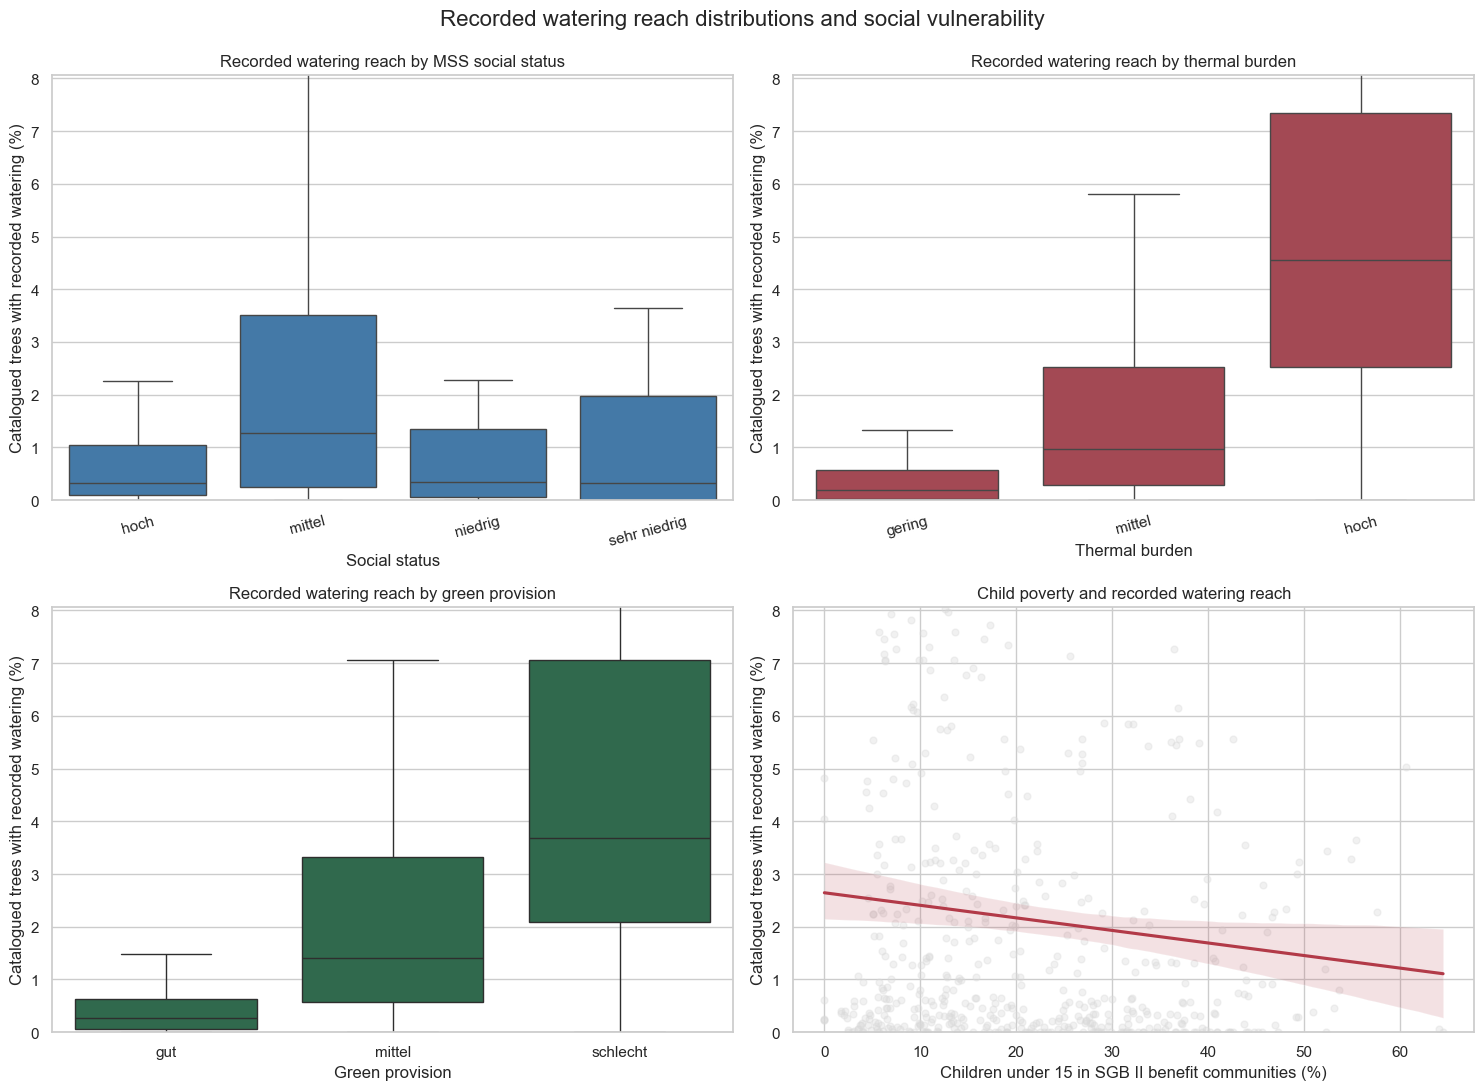

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(
    data=analysis,
    x="si_v",
    y="watering_reach_pct",
    order=social_order,
    showfliers=False,
    color=COLORS["blue"],
    ax=axes[0, 0],
)
axes[0, 0].set_title("Recorded watering reach by MSS social status")
axes[0, 0].set_xlabel("Social status")
axes[0, 0].set_ylabel("Catalogued trees with recorded watering (%)")

sns.boxplot(
    data=analysis,
    x="thermal_burden",
    y="watering_reach_pct",
    order=thermal_order,
    showfliers=False,
    color=COLORS["red"],
    ax=axes[0, 1],
)
axes[0, 1].set_title("Recorded watering reach by thermal burden")
axes[0, 1].set_xlabel("Thermal burden")
axes[0, 1].set_ylabel("Catalogued trees with recorded watering (%)")

sns.boxplot(
    data=analysis,
    x="green_provision",
    y="watering_reach_pct",
    order=green_order,
    showfliers=False,
    color=COLORS["green"],
    ax=axes[1, 0],
)
axes[1, 0].set_title("Recorded watering reach by green provision")
axes[1, 0].set_xlabel("Green provision")
axes[1, 0].set_ylabel("Catalogued trees with recorded watering (%)")

sns.regplot(
    data=analysis,
    x="s4",
    y="watering_reach_pct",
    scatter_kws={"alpha": 0.35, "s": 24},
    line_kws={"color": COLORS["red"]},
    color=COLORS["gray"],
    ax=axes[1, 1],
)
axes[1, 1].set_title("Child poverty and recorded watering reach")
axes[1, 1].set_xlabel("Children under 15 in SGB II benefit communities (%)")
axes[1, 1].set_ylabel("Catalogued trees with recorded watering (%)")

reach_plot_cap = analysis["watering_reach_pct"].quantile(0.95)
for ax in axes.flat:
    ax.set_ylim(0, reach_plot_cap)
for ax in axes[0, :]:
    ax.tick_params(axis="x", rotation=15)

fig.suptitle(
    "Recorded watering reach distributions and social vulnerability",
    fontsize=16,
    y=0.99,
)
plt.tight_layout()
plt.savefig(
    FIGURES / "02_watering_equity_distributions.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

Boxplots suppress outlier points and share a y-axis capped at the 95th
percentile for readability. All observations remain in the calculations.

## 4. Citywide and district-adjusted rank associations

In [7]:
def district_adjusted_rank_association(frame, x, y):
    complete = frame[[x, y, "District"]].dropna().copy()
    x_rank = complete[x].rank(method="average")
    y_rank = complete[y].rank(method="average")
    x_residual = x_rank - x_rank.groupby(complete["District"]).transform("mean")
    y_residual = y_rank - y_rank.groupby(complete["District"]).transform("mean")
    coefficient, p_value = pearsonr(x_residual, y_residual)
    return coefficient, p_value


predictors = {
    "MSS social status score (1 high - 4 very low)": "social_status_score",
    "S1 unemployment (%)": "s1",
    "S2 children in single-parent households (%)": "s2",
    "S3 transfer receipt (%)": "s3",
    "S4 child poverty (%)": "s4",
    "Environmental and social burden count": "multiple_burden_count",
}
outcomes = {
    "Watering reach (%)": "watering_reach_pct",
    "Litres per inventory tree": "litres_per_inventory_tree",
}

association_rows = []
for predictor_label, predictor in predictors.items():
    for outcome_label, outcome in outcomes.items():
        complete = analysis[[predictor, outcome]].dropna()
        rho, p_value = spearmanr(complete[predictor], complete[outcome])
        adjusted_rho, adjusted_p = district_adjusted_rank_association(
            analysis, predictor, outcome
        )
        association_rows.append(
            {
                "predictor": predictor_label,
                "outcome": outcome_label,
                "n": len(complete),
                "spearman_rho": rho,
                "spearman_p": p_value,
                "district_adjusted_rank_r": adjusted_rho,
                "district_adjusted_p": adjusted_p,
            }
        )

associations = pd.DataFrame(association_rows)
associations.to_csv(TABLES / "equity_associations.csv", index=False)
display(
    associations.style.format(
        {
            "spearman_rho": "{:.3f}",
            "spearman_p": "{:.4f}",
            "district_adjusted_rank_r": "{:.3f}",
            "district_adjusted_p": "{:.4f}",
        }
    )
)

,predictor,outcome,n,spearman_rho,spearman_p,district_adjusted_rank_r,district_adjusted_p
0,MSS social status score (1 high - 4 very low),Watering reach (%),535,-0.025,0.5686,-0.003,0.9361
1,MSS social status score (1 high - 4 very low),Litres per inventory tree,535,-0.077,0.0741,-0.066,0.1294
2,S1 unemployment (%),Watering reach (%),535,-0.057,0.1904,-0.039,0.3714
3,S1 unemployment (%),Litres per inventory tree,535,-0.110,0.0107,-0.106,0.0138
4,S2 children in single-parent households (%),Watering reach (%),535,-0.097,0.0255,-0.011,0.7942
5,S2 children in single-parent households (%),Litres per inventory tree,535,-0.124,0.0041,-0.043,0.3178
6,S3 transfer receipt (%),Watering reach (%),535,-0.071,0.0993,-0.036,0.4069
7,S3 transfer receipt (%),Litres per inventory tree,535,-0.123,0.0045,-0.103,0.0167
8,S4 child poverty (%),Watering reach (%),535,-0.123,0.0043,-0.090,0.0365
9,S4 child poverty (%),Litres per inventory tree,535,-0.173,0.0001,-0.158,0.0002


The district-adjusted statistic is a partial rank association: citywide ranks
for both variables are residualized against district indicators, then
correlated. It asks whether the relationship remains within districts rather
than being explained only by differences between Berlin's 12 districts.

P-values remain exploratory because the LOR observations are spatially
autocorrelated and multiple hypotheses are examined.

## 5. Small-denominator sensitivity

In [8]:
sensitivity_rows = []
for minimum_inventory in [1, 100, 500]:
    subset = analysis[analysis["inventory_trees"] >= minimum_inventory]
    for predictor_label, predictor in {
        "S4 child poverty (%)": "s4",
        "Environmental and social burden count": "multiple_burden_count",
    }.items():
        for outcome_label, outcome in outcomes.items():
            rho, p_value = spearmanr(subset[predictor], subset[outcome])
            sensitivity_rows.append(
                {
                    "minimum_inventory_trees": minimum_inventory,
                    "predictor": predictor_label,
                    "outcome": outcome_label,
                    "n": len(subset),
                    "spearman_rho": rho,
                    "p_value": p_value,
                }
            )

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(TABLES / "sensitivity_inventory_thresholds.csv", index=False)
display(
    sensitivity.style.format(
        {"spearman_rho": "{:.3f}", "p_value": "{:.4f}"}
    )
)

,minimum_inventory_trees,predictor,outcome,n,spearman_rho,p_value
0,1,S4 child poverty (%),Watering reach (%),535,-0.123,0.0043
1,1,S4 child poverty (%),Litres per inventory tree,535,-0.173,0.0001
2,1,Environmental and social burden count,Watering reach (%),535,0.486,0.0000
3,1,Environmental and social burden count,Litres per inventory tree,535,0.431,0.0000
4,100,S4 child poverty (%),Watering reach (%),533,-0.120,0.0054
5,100,S4 child poverty (%),Litres per inventory tree,533,-0.171,0.0001
6,100,Environmental and social burden count,Watering reach (%),533,0.493,0.0000
7,100,Environmental and social burden count,Litres per inventory tree,533,0.437,0.0000
8,500,S4 child poverty (%),Watering reach (%),475,-0.116,0.0118
9,500,S4 child poverty (%),Litres per inventory tree,475,-0.174,0.0001


## 6. Transparent priority candidates

In [9]:
analysis["social_need"] = (analysis["social_status_score"] - 1) / 3
analysis["thermal_need"] = (analysis["thermal_burden_score"] - 1) / 2
analysis["green_need"] = (analysis["green_deficit_score"] - 1) / 2
analysis["need_index"] = analysis[
    ["social_need", "thermal_need", "green_need"]
].mean(axis=1)
analysis["watering_supply_rank"] = analysis["watering_reach_pct"].rank(pct=True)
analysis["priority_gap"] = (
    analysis["need_index"] - analysis["watering_supply_rank"]
)

city_median_reach = analysis["watering_reach_pct"].median()
analysis["priority_candidate"] = (
    analysis["social_status_score"].ge(3)
    & (
        analysis["thermal_burden"].eq("hoch")
        | analysis["green_provision"].eq("schlecht")
    )
    & analysis["watering_reach_pct"].lt(city_median_reach)
)

candidate_columns = [
    "plr_id", "plr_name", "bzr_name", "District",
    "inventory_trees", "watered_trees", "watering_reach_pct",
    "litres_per_inventory_tree", "si_v", "s4",
    "thermal_burden", "green_provision", "multiple_burden",
    "need_index", "watering_supply_rank", "priority_gap",
]
priority_candidates = (
    analysis.loc[analysis["priority_candidate"], candidate_columns]
    .sort_values("priority_gap", ascending=False)
)
priority_candidates.to_csv(
    TABLES / "priority_gap_planungsraeume.csv",
    index=False,
)

print(
    f"Priority candidates: {len(priority_candidates)} of "
    f"{len(analysis)} valid Planungsräume"
)
display(
    priority_candidates.style.format(
        {
            "watering_reach_pct": "{:.2f}",
            "litres_per_inventory_tree": "{:.2f}",
            "s4": "{:.1f}",
            "need_index": "{:.2f}",
            "watering_supply_rank": "{:.2f}",
            "priority_gap": "{:.2f}",
        }
    )
)

Priority candidates: 10 of 535 valid Planungsräume


,plr_id,plr_name,bzr_name,District,inventory_trees,watered_trees,watering_reach_pct,litres_per_inventory_tree,si_v,s4,thermal_burden,green_provision,multiple_burden,need_index,watering_supply_rank,priority_gap
20,01200521,Zwinglistraße,Moabit West,Mitte,244.000000,0.000000,0.00,0.00,niedrig,42.3,hoch,schlecht,fünffach,0.89,0.07,0.82
237,05300840,Nonnendammallee,Siemensstadt,Spandau,550.000000,0.000000,0.00,0.00,sehr niedrig,52.3,mittel,schlecht,zweifach,0.83,0.07,0.76
514,12200309,Scharnweberstraße,West 4 - Auguste-Viktoria-Allee,Reinickendorf,808.000000,0.000000,0.00,0.00,sehr niedrig,47.3,mittel,schlecht,dreifach,0.83,0.07,0.76
372,08401138,Goldhähnchenweg,Buckow Nord,Neukölln,48.000000,0.000000,0.00,0.00,sehr niedrig,42.6,gering,schlecht,dreifach,0.67,0.07,0.60
355,08100521,Schulenburgpark,Köllnische Heide,Neukölln,1703.000000,1.000000,0.06,0.03,sehr niedrig,64.0,hoch,gut,vierfach,0.67,0.17,0.50
371,08301037,Gropiusstadt Süd-Ost,Gropiusstadt Ost,Neukölln,356.000000,0.000000,0.00,0.00,niedrig,42.1,gering,schlecht,dreifach,0.56,0.07,0.49
211,05100314,Kurstraße,Spandau Mitte,Spandau,767.000000,3.000000,0.39,1.15,sehr niedrig,51.0,mittel,schlecht,dreifach,0.83,0.39,0.44
540,12601235,Dannenwalder Weg,MV Süd,Reinickendorf,697.000000,1.000000,0.14,1.95,sehr niedrig,47.0,gering,schlecht,vierfach,0.67,0.24,0.43
177,04400833,Schlangenbader Straße,Schmargendorf,Charlottenburg-Wilmersdorf,720.000000,4.000000,0.56,0.22,niedrig,28.4,mittel,schlecht,zweifach,0.72,0.45,0.27
433,10100210,Marzahner Promenade,Marzahn Mitte,Marzahn-Hellersdorf,2930.000000,12.000000,0.41,0.10,niedrig,33.5,gering,schlecht,dreifach,0.56,0.40,0.15


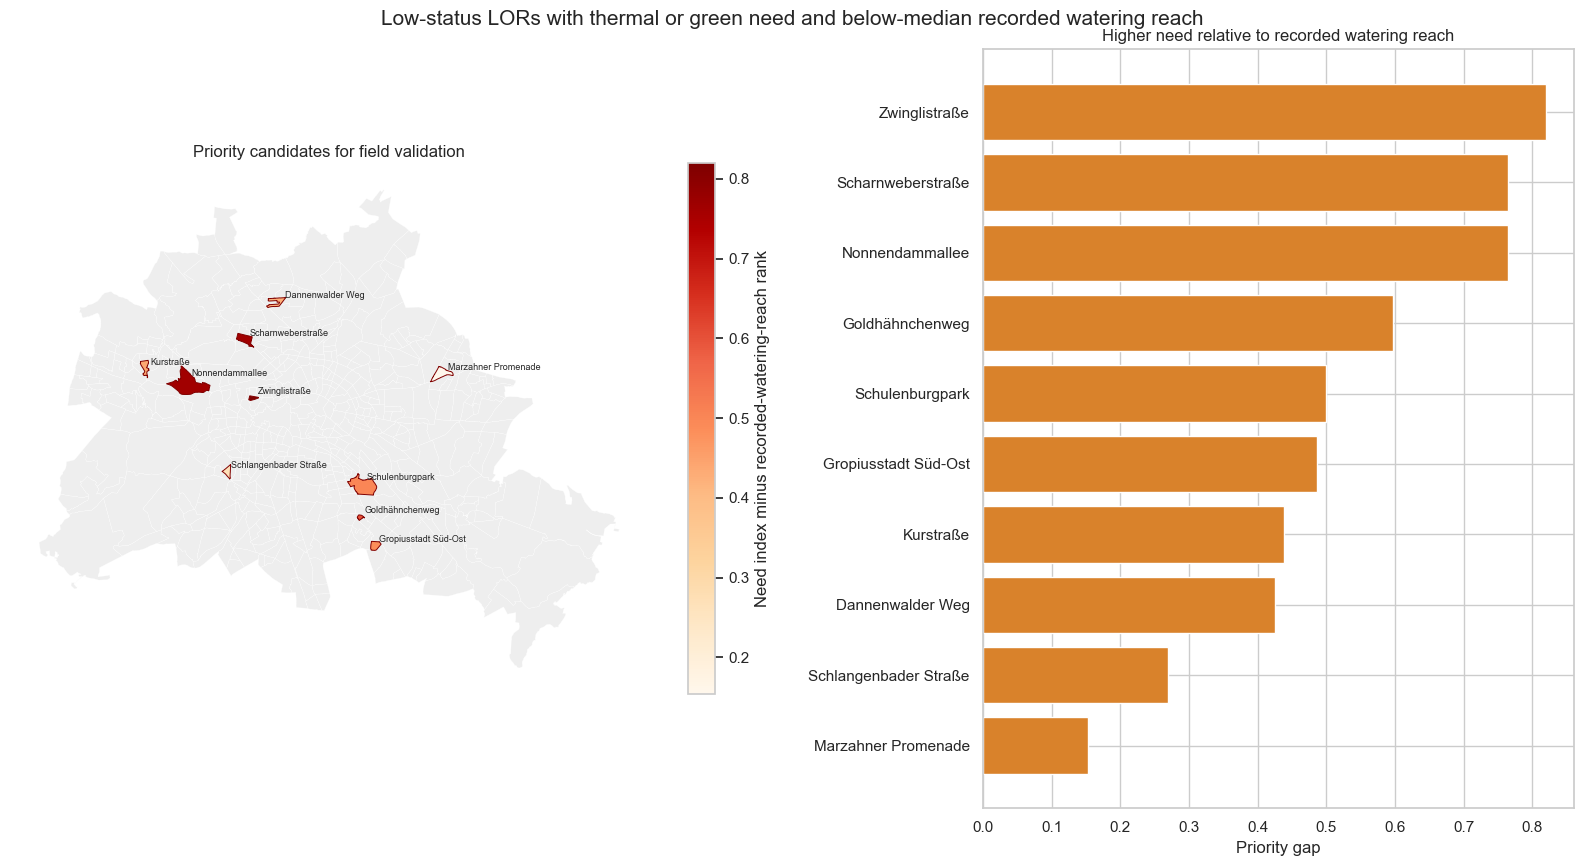

In [10]:
candidate_map = panel.merge(
    analysis[["plr_id", "priority_candidate", "priority_gap"]],
    on="plr_id",
    how="left",
)
candidate_map["priority_candidate"] = candidate_map[
    "priority_candidate"
].fillna(False)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [1.35, 1]}
)
candidate_map.plot(
    color="#eeeeee",
    edgecolor="white",
    linewidth=0.2,
    ax=axes[0],
)
candidate_map[candidate_map["priority_candidate"]].plot(
    column="priority_gap",
    cmap="OrRd",
    edgecolor="#7f0000",
    linewidth=0.7,
    legend=True,
    legend_kwds={"label": "Need index minus recorded-watering-reach rank", "shrink": 0.7},
    ax=axes[0],
)
for _, row in candidate_map[candidate_map["priority_candidate"]].iterrows():
    point = row.geometry.representative_point()
    axes[0].annotate(
        row["plr_name"],
        (point.x, point.y),
        fontsize=6.5,
        xytext=(3, 3),
        textcoords="offset points",
    )
axes[0].set_title("Priority candidates for field validation")
axes[0].set_axis_off()

bar_data = priority_candidates.sort_values("priority_gap")
axes[1].barh(
    bar_data["plr_name"],
    bar_data["priority_gap"],
    color=COLORS["orange"],
)
axes[1].set_xlabel("Priority gap")
axes[1].set_ylabel("")
axes[1].set_title("Higher need relative to recorded watering reach")

fig.suptitle(
    "Low-status LORs with thermal or green need and below-median recorded watering reach",
    fontsize=15,
    y=0.96,
)
plt.tight_layout()
plt.savefig(
    FIGURES / "03_priority_gap_candidates.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

The priority rule is intentionally explicit:

- MSS status is low or very low;
- thermal burden is high or green provision is poor; and
- watering reach is below the citywide median.

The equal-weighted `need_index` and rank-based `priority_gap` order candidates
for inspection; they are not validated policy allocation weights. Platform
adoption, municipal watering, private watering, and tree-level water demand are
not observed here, so candidate areas require local validation.

## 7. Export analysis-ready results

In [11]:
analysis_fields = [
    "plr_id", "plr_name", "bzr_id", "bzr_name", "District",
    "inventory_trees", "watered_trees", "watering_events", "total_litres",
    "watering_reach_pct", "litres_per_inventory_tree",
    "mss_population", "social_status_score", "si_v", "di_v", "sdi_v",
    "s1", "s2", "s3", "s4",
    "thermal_burden", "green_provision", "noise_burden", "air_burden",
    "multiple_burden", "multiple_burden_count",
    "priority_candidate", "need_index", "watering_supply_rank", "priority_gap",
]

analysis.drop(columns="geometry")[analysis_fields].to_csv(
    TABLES / "lor_watering_equity_metrics.csv",
    index=False,
)

export_panel = panel.merge(
    analysis[
        [
            "plr_id", "priority_candidate", "need_index",
            "watering_supply_rank", "priority_gap",
        ]
    ],
    on="plr_id",
    how="left",
)
output_gpkg = OUT / "lor_watering_equity_2020_2025.gpkg"
if output_gpkg.exists():
    output_gpkg.unlink()
export_panel.to_file(
    output_gpkg,
    layer="lor_watering_equity",
    driver="GPKG",
)

print(
    "Saved analysis table: "
    f"{(TABLES / 'lor_watering_equity_metrics.csv').relative_to(ROOT)}"
)
print(f"Saved enriched polygons: {output_gpkg.relative_to(ROOT)}")

Saved analysis table: output/equity/tables/lor_watering_equity_metrics.csv
Saved enriched polygons: output/equity/lor_watering_equity_2020_2025.gpkg


## 8. Reproducible findings summary

In [12]:
def association_value(predictor, outcome, column):
    row = associations[
        associations["predictor"].eq(predictor)
        & associations["outcome"].eq(outcome)
    ].iloc[0]
    return float(row[column])


findings = {
    "valid_lor_observations": len(analysis),
    "median_watering_reach_pct": analysis["watering_reach_pct"].median(),
    "median_reach_high_status": social_summary.loc[
        social_summary["si_v"].eq("hoch"), "median"
    ].iloc[0],
    "median_reach_middle_status": social_summary.loc[
        social_summary["si_v"].eq("mittel"), "median"
    ].iloc[0],
    "median_reach_low_status": social_summary.loc[
        social_summary["si_v"].eq("niedrig"), "median"
    ].iloc[0],
    "median_reach_very_low_status": social_summary.loc[
        social_summary["si_v"].eq("sehr niedrig"), "median"
    ].iloc[0],
    "child_poverty_reach_rho": association_value(
        "S4 child poverty (%)", "Watering reach (%)", "spearman_rho"
    ),
    "child_poverty_reach_district_adjusted_r": association_value(
        "S4 child poverty (%)",
        "Watering reach (%)",
        "district_adjusted_rank_r",
    ),
    "burden_reach_rho": association_value(
        "Environmental and social burden count",
        "Watering reach (%)",
        "spearman_rho",
    ),
    "priority_candidates": len(priority_candidates),
}

print("Key reproducible results")
for key, value in findings.items():
    print(f"- {key}: {value}")

Key reproducible results
- valid_lor_observations: 535
- median_watering_reach_pct: 0.6632277081798084
- median_reach_high_status: 0.32291791494601596
- median_reach_middle_status: 1.272264631043257
- median_reach_low_status: 0.34057045551298426
- median_reach_very_low_status: 0.321458373451441
- child_poverty_reach_rho: -0.12312424672524656
- child_poverty_reach_district_adjusted_r: -0.09042672355115193
- burden_reach_rho: 0.4858816027861374
- priority_candidates: 10


## Preliminary interpretation

- Watering is not distributed monotonically across MSS social-status classes.
  Middle-status Planungsräume have the highest median reach, while both the
  high-status and low/very-low-status groups are lower.
- Recorded watering aligns strongly with the Environmental Justice Atlas burden
  count and is higher in thermally burdened and poorly green-provided areas.
  This likely reflects concentration in dense inner-city neighbourhoods and
  should not be interpreted as a causal response to environmental need.
- Child poverty has a small negative relationship with watering reach and
  intensity. The association weakens but remains negative after controlling
  for district through rank residualization.
- The coexistence of environmental alignment and incomplete social
  equity means a single "watering follows need" conclusion would be misleading.
- The screening-candidate list is the next practical unit for validation against
  municipal watering, platform participation, drought exposure, and tree-level
  need.

These descriptive results informed H3. A hypothesis-guided validation analysis
requires the care measures, component transformations, weights, geography,
exclusions, and multiplicity handling to be locked first. Weather integration
will use ERA5 for harmonised temporal controls and DWD station observations for
sensitivity and plausibility context. Static equity variables can enter as
effect modifiers or screening criteria rather than outcomes.